In [1]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"  # must be set before torch initializes CUDA

import importlib
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, "kev")

import data.persona as _persona_mod
import data.base as _base_mod
import data.issp as _issp_mod
import data.twin2k as _twin2k_mod
import data.grummon as _grummon_mod
import models.kev_pointer as _kev_pointer_mod
import training.plotter as _plotter_mod
import training.trainer as _trainer_mod
import training as _training_pkg

for _mod in (
    _persona_mod,
    _base_mod,
    _issp_mod,
    _twin2k_mod,
    _grummon_mod,
    _kev_pointer_mod,
    _plotter_mod,
    _trainer_mod,
    _training_pkg,
):
    importlib.reload(_mod)

from data.base import build_eval_set, build_persona_dataset, group_train_records
from data.issp import load_issp_df
from data.twin2k import load_twin2k_df
from training import GroupedTrainer, free_gpu

## 1. Load Valid Set & Build 100-Step Training Subset (0.8B)

In [2]:
INCLUDE_COUNTRY = False
TARGET_STEPS = 100
BATCH_SIZE = 1
GRAD_ACCUM_STEPS = 12
MAX_QUESTIONS_PER_GROUP = 32
MAX_CHARS_PER_GROUP = 20_000
SUBSET_SEED = 0

VALID_ISSP_QIDS = ["2020:v12", "2020:v6", "2020:v28", "2020:v42"]
VALID_TWIN_QIDS = [f"twin2k:QID9_{i:03d}" for i in range(89, 100)] + ["twin2k:QID41", "twin2k:QID163", "twin2k:QID165"]
VALID_QIDS = VALID_ISSP_QIDS + VALID_TWIN_QIDS

all_df = pd.concat([load_issp_df(), load_twin2k_df()], ignore_index=True)
if not set(VALID_QIDS) <= set(all_df["qid"]):
    raise KeyError(f"Valid qids not found: {sorted(set(VALID_QIDS) - set(all_df['qid']))}")

full_train_records = build_persona_dataset(
    all_df[~all_df["qid"].isin(VALID_QIDS)], attr_sets=None, include_country=INCLUDE_COUNTRY, desc="train_records_resp"
)
valid_grouped = build_eval_set(
    all_df[all_df["qid"].isin(VALID_QIDS)],
    attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, name="valid", valid=True,
)
eval_records = [valid_grouped]

# Select exactly TARGET_STEPS * BATCH_SIZE * GRAD_ACCUM_STEPS groups with distinct persona keys
# so GroupedTrainer always produces exactly TARGET_STEPS = 100 steps.
target_groups = TARGET_STEPS * BATCH_SIZE * GRAD_ACCUM_STEPS
all_groups = group_train_records(
    full_train_records,
    max_questions=MAX_QUESTIONS_PER_GROUP,
    max_chars=MAX_CHARS_PER_GROUP,
    rng=random.Random(SUBSET_SEED),
)
seen_pkeys = set()
selected_groups = []
for g in all_groups:
    pkey = tuple(sorted(g[0]["personas"].items()))
    if pkey not in seen_pkeys:
        seen_pkeys.add(pkey)
        selected_groups.append(g)
        if len(selected_groups) == target_groups:
            break
if len(selected_groups) != target_groups:
    raise ValueError(f"Expected {target_groups} groups, got {len(selected_groups)}")

train_subset = [r for g in selected_groups for r in g]

print(
    f"Full train records : {len(full_train_records):,}\n"
    f"100-step subset    : {len(train_subset):,} records across {len(selected_groups):,} groups ({TARGET_STEPS} steps)\n"
    f"Valid eval set     : {len(valid_grouped['records']):,} records ({len(valid_grouped['packed_views']):,} states)"
)

Loaded 1,881,950 records from train_records_resp_minNone_5099daf2.pkl
Loaded 13,183 records from valid_records_minNone_dc60d6c3.pkl
Full train records : 1,881,950
100-step subset    : 30,759 records across 1,200 groups (100 steps)
Valid eval set     : 13,183 records (3,879 states)


In [5]:
len(train_subset)
train_subset[0]

{'qid': 'twin2k:QID29_23',
 'year': 'twin2k',
 'v': 'QID29_23',
 'type': 'score',
 'question': 'Below are 24 different values that people rate of different importance in their lives. FIRST READ THROUGH THE LIST to familiarize yourself with all the values. While reading over the list, consider which ones tend to be most important to you and which tend to be least important to you. After familiarizing yourself with the list, rate the relative importance of each value to you as “A GUIDING PRINCIPLE IN MY LIFE.” It is important to spread your ratings out as best you can—be sure to use some numbers in the lower range, some in the middle range, and some in the higher range. Avoid using too many similar numbers. Work fairly quickly. TRADITION (showing respect for family and cultural values)',
 'option_texts': ['Not Important to me 1',
  '2',
  '3',
  '4',
  'Quite Important to me 5',
  '6',
  '7',
  '8',
  'Highly Important to me 9'],
 'personas': {'SEX': 'Female',
  'AGE': '30-49',
  'EDULEV

## 2. Shared 0.8B Tuning Helper

Each strategy cell below runs 100 steps from the same initial `jaredpalmer/kev-0.8b` weights and `seed=0`, evaluates on `valid` every 10 steps, and stores its `TrainingPlotter` in `lr_tuning_runs[name]`.

In [6]:
LR = 5e-5
WARMUP_STEPS = 5      # 5% of 100 steps
VAL_EVERY = 10        # evaluate on valid every 10 steps (0, 10, 20, ..., 100)
SEED = 0

lr_tuning_runs = {}

def run_lr_strategy(run_slug, label, *, lr_schedule="onecycle", min_lr=None, decay_pct=0.20):
    free_gpu()
    trainer = GroupedTrainer(
        train_records=train_subset,
        eval_records=eval_records,
        base_model="jaredpalmer/kev-0.8b",
        save_dir=f"runs/test-kev-0.8b-lrtune-{run_slug}",
        lora_rank=64,
        weights_dtype="bf16",
        use_bf16=True,
        eval_bf16=True,
        gradient_checkpointing=False,
        epochs=1,
        lr=LR,
        min_lr=min_lr,
        lr_schedule=lr_schedule,
        decay_pct=decay_pct,
        warmup_steps=WARMUP_STEPS,
        batch_size=BATCH_SIZE,
        grad_accum_steps=GRAD_ACCUM_STEPS,
        max_questions_per_group=MAX_QUESTIONS_PER_GROUP,
        max_chars_per_group=MAX_CHARS_PER_GROUP,
        eval_max_questions=1024,
        eval_max_chars=360_000,
        val_every=VAL_EVERY,
        save_every=None,
        seed=SEED,
        resume=False,
        free_model_on_exit=True,
    )
    if trainer.total_steps != TARGET_STEPS:
        raise AssertionError(f"Expected total_steps={TARGET_STEPS}, got {trainer.total_steps}")
    display(pd.Series(trainer.describe(), name=label).to_frame())
    plotter = trainer.train()
    lr_tuning_runs[label] = plotter
    return plotter

## Strategy 1: `OneCycleLR` (Default — 0% Floor, `min_lr=None`)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,1. OneCycle (current: 0% floor)
run_name,test-kev-0.8b-lrtune-onecycle-floor0
save_dir,runs/test-kev-0.8b-lrtune-onecycle-floor0
init_from,jaredpalmer/kev-0.8b
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64
resume,False
seed,0
epochs,1
lr_schedule,onecycle


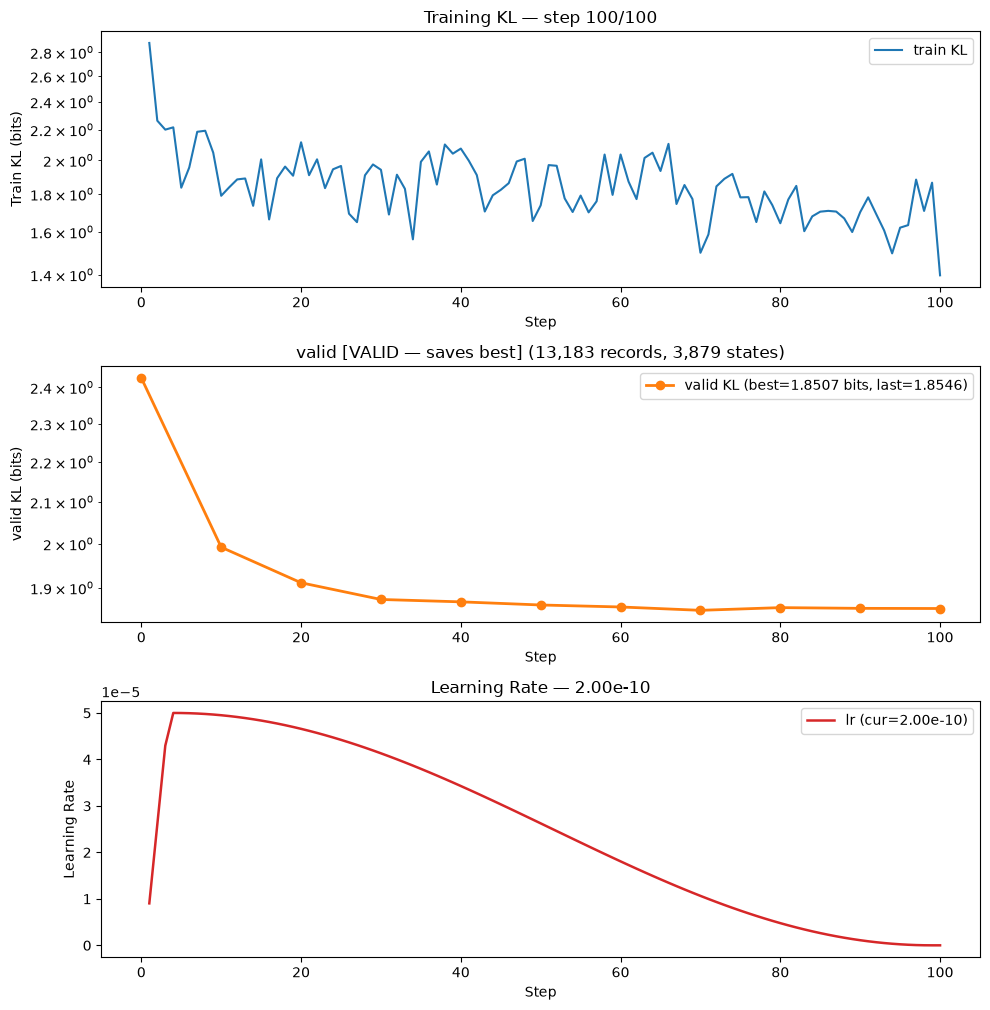

,epoch,step,train_kl,valid_kl
0,0,0,—,2.4262
1,1,10,1.7900,1.9919
2,1,20,2.1149,1.9111
3,1,30,1.9411,1.8743
4,1,40,2.0738,1.8691
5,1,50,1.7376,1.8623
6,1,60,2.0358,1.8580
7,1,70,1.4987,1.8507
8,1,80,1.6432,1.8566
9,1,90,1.7011,1.8550


In [7]:
plotter_onecycle_0 = run_lr_strategy(
    "onecycle-floor0",
    "1. OneCycle (current: 0% floor)",
    lr_schedule="onecycle",
    min_lr=None,
)

## Strategy 2: `OneCycleLR` + 10% Floor (`min_lr=5e-6`)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,2. OneCycle + 10% floor (5e-6)
run_name,test-kev-0.8b-lrtune-onecycle-floor10
save_dir,runs/test-kev-0.8b-lrtune-onecycle-floor10
init_from,jaredpalmer/kev-0.8b
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64
resume,False
seed,0
epochs,1
lr_schedule,onecycle


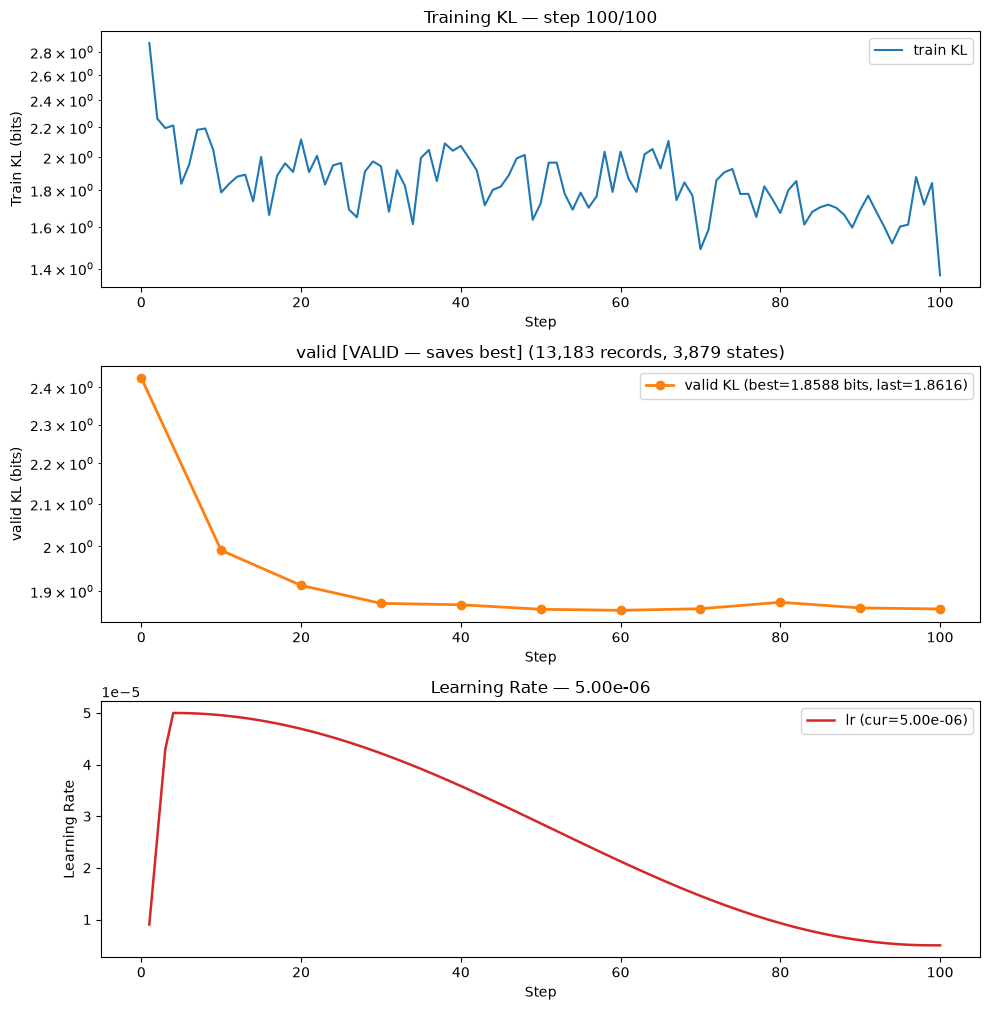

,epoch,step,train_kl,valid_kl
0,0,0,—,2.4262
1,1,10,1.7863,1.9911
2,1,20,2.1169,1.9127
3,1,30,1.9432,1.8736
4,1,40,2.0731,1.8707
5,1,50,1.7255,1.8610
6,1,60,2.0350,1.8588
7,1,70,1.4899,1.8622
8,1,80,1.6724,1.8760
9,1,90,1.6880,1.8639


In [8]:
plotter_onecycle_10 = run_lr_strategy(
    "onecycle-floor10",
    "2. OneCycle + 10% floor (5e-6)",
    lr_schedule="onecycle",
    min_lr=5e-6,
)

## Strategy 3: `OneCycleLR` + 20% Floor (`min_lr=1e-5`)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,3. OneCycle + 20% floor (1e-5)
run_name,test-kev-0.8b-lrtune-onecycle-floor20
save_dir,runs/test-kev-0.8b-lrtune-onecycle-floor20
init_from,jaredpalmer/kev-0.8b
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64
resume,False
seed,0
epochs,1
lr_schedule,onecycle


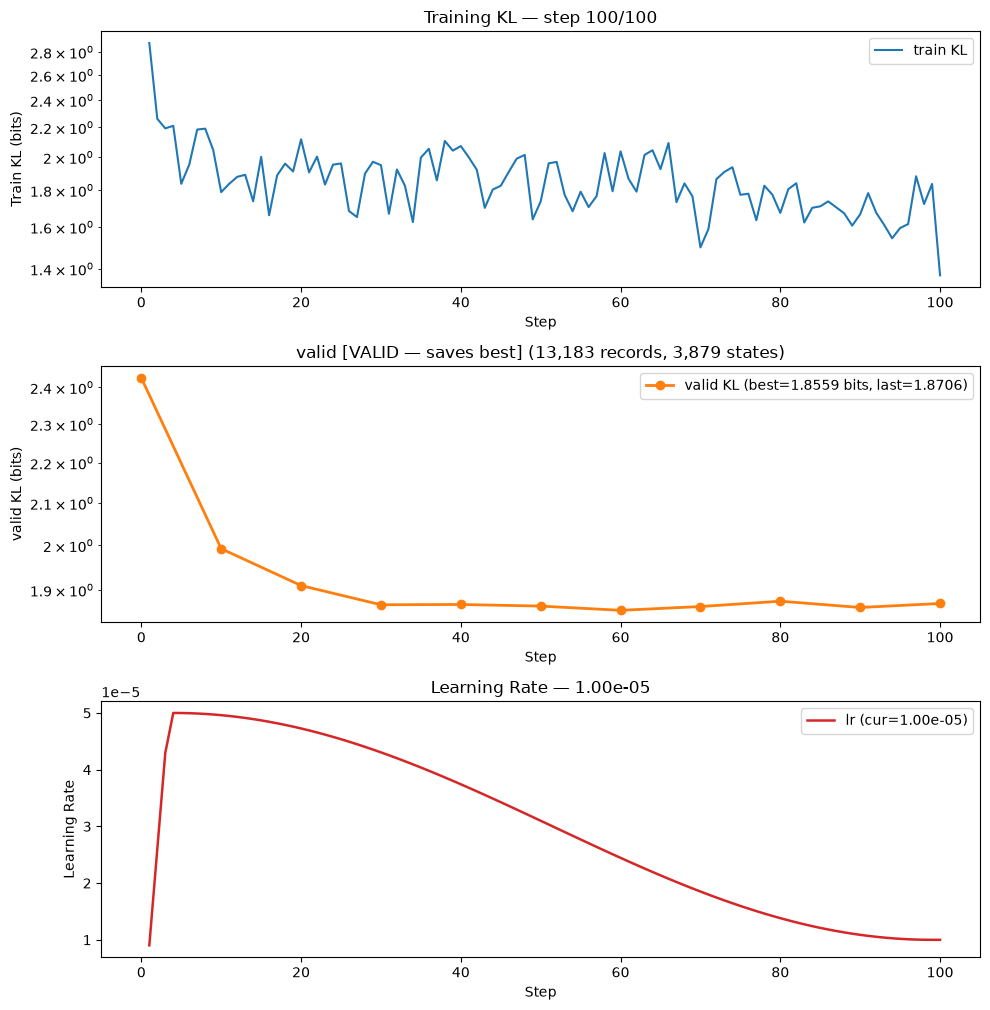

,epoch,step,train_kl,valid_kl
0,0,0,—,2.4262
1,1,10,1.7890,1.9925
2,1,20,2.1181,1.9097
3,1,30,1.9500,1.8678
4,1,40,2.0729,1.8684
5,1,50,1.7367,1.8650
6,1,60,2.0381,1.8559
7,1,70,1.4992,1.8640
8,1,80,1.6739,1.8755
9,1,90,1.6667,1.8620


In [9]:
plotter_onecycle_20 = run_lr_strategy(
    "onecycle-floor20",
    "3. OneCycle + 20% floor (1e-5)",
    lr_schedule="onecycle",
    min_lr=1e-5,
)

## Strategy 4: `OneCycleLR` + 40% Floor (`min_lr=2e-5`)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,4. OneCycle + 40% floor (2e-5)
run_name,test-kev-0.8b-lrtune-onecycle-floor40
save_dir,runs/test-kev-0.8b-lrtune-onecycle-floor40
init_from,jaredpalmer/kev-0.8b
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64
resume,False
seed,0
epochs,1
lr_schedule,onecycle


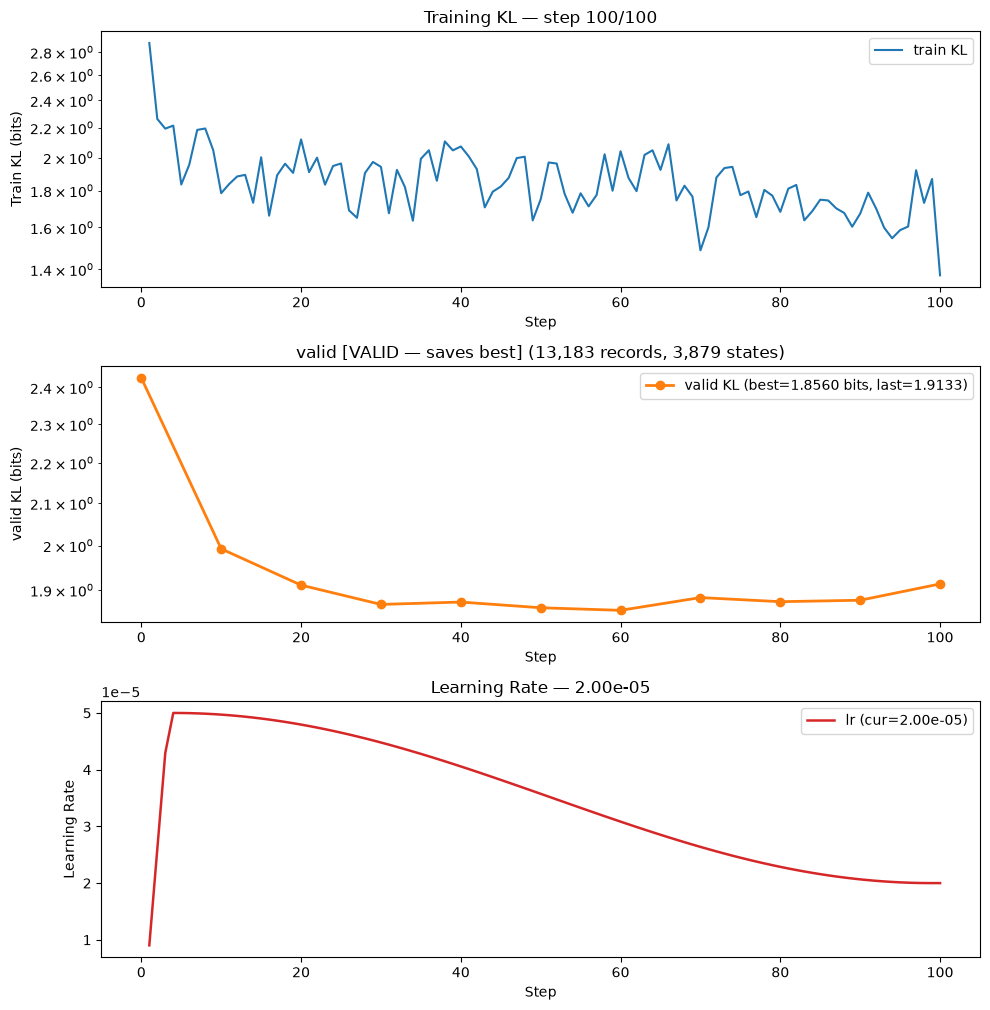

,epoch,step,train_kl,valid_kl
0,0,0,—,2.4262
1,1,10,1.7851,1.9923
2,1,20,2.1190,1.9107
3,1,30,1.9413,1.8687
4,1,40,2.0718,1.8738
5,1,50,1.7506,1.8615
6,1,60,2.0406,1.8560
7,1,70,1.4876,1.8834
8,1,80,1.6819,1.8745
9,1,90,1.6724,1.8777


In [10]:
plotter_onecycle_40 = run_lr_strategy(
    "onecycle-floor40",
    "4. OneCycle + 40% floor (2e-5)",
    lr_schedule="onecycle",
    min_lr=2e-5,
)

## Strategy 5: `OneCycleLR` + 50% Floor (`min_lr=2.5e-5`)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,5. OneCycle + 50% floor (2.5e-5)
run_name,test-kev-0.8b-lrtune-onecycle-floor50
save_dir,runs/test-kev-0.8b-lrtune-onecycle-floor50
init_from,jaredpalmer/kev-0.8b
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64
resume,False
seed,0
epochs,1
lr_schedule,onecycle


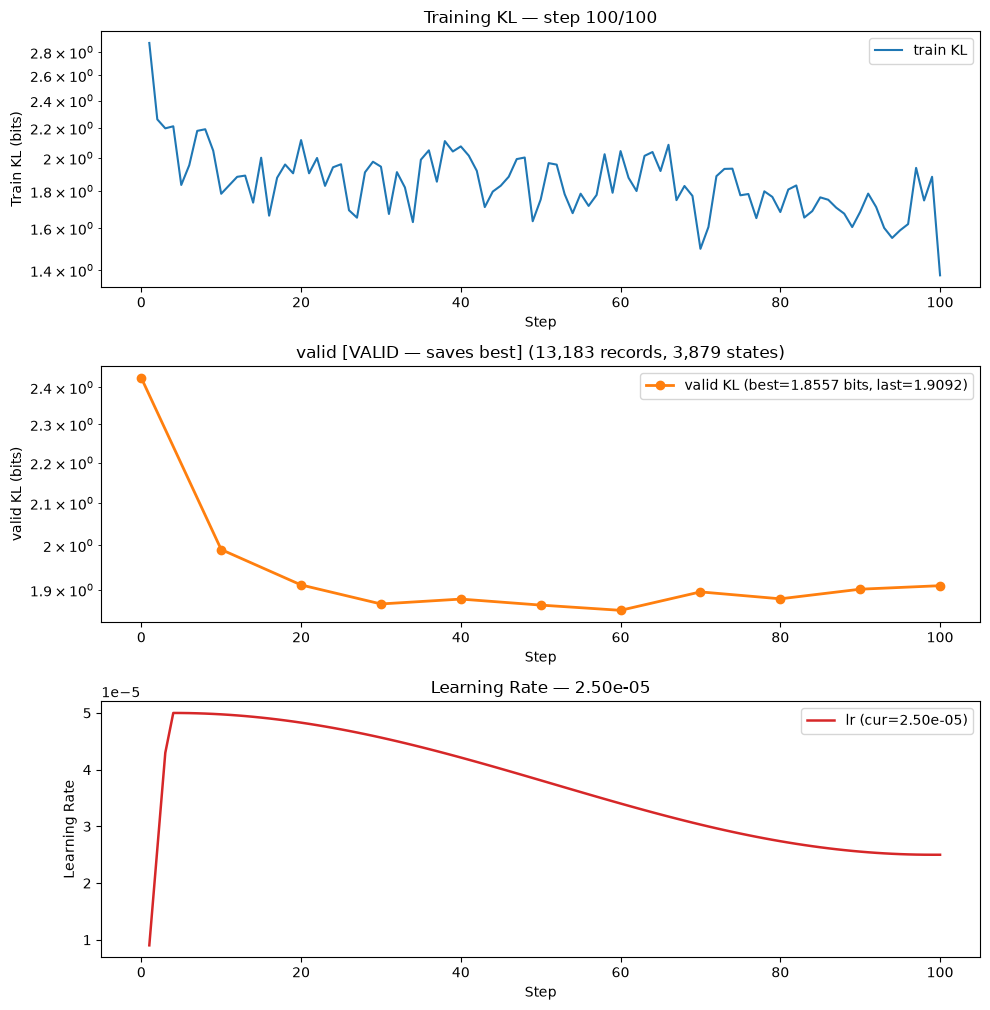

,epoch,step,train_kl,valid_kl
0,0,0,—,2.4262
1,1,10,1.7849,1.9904
2,1,20,2.1170,1.9108
3,1,30,1.9453,1.8694
4,1,40,2.0748,1.8799
5,1,50,1.7528,1.8669
6,1,60,2.0441,1.8557
7,1,70,1.4985,1.8956
8,1,80,1.6842,1.8805
9,1,90,1.6852,1.9015


In [11]:
plotter_onecycle_50 = run_lr_strategy(
    "onecycle-floor50",
    "5. OneCycle + 50% floor (2.5e-5)",
    lr_schedule="onecycle",
    min_lr=2.5e-5,
)

## Strategy 6: Linear Decay + 10% Floor (`min_lr=5e-6`)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,6. Linear + 10% floor (5e-6)
run_name,test-kev-0.8b-lrtune-linear-floor10
save_dir,runs/test-kev-0.8b-lrtune-linear-floor10
init_from,jaredpalmer/kev-0.8b
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64
resume,False
seed,0
epochs,1
lr_schedule,linear


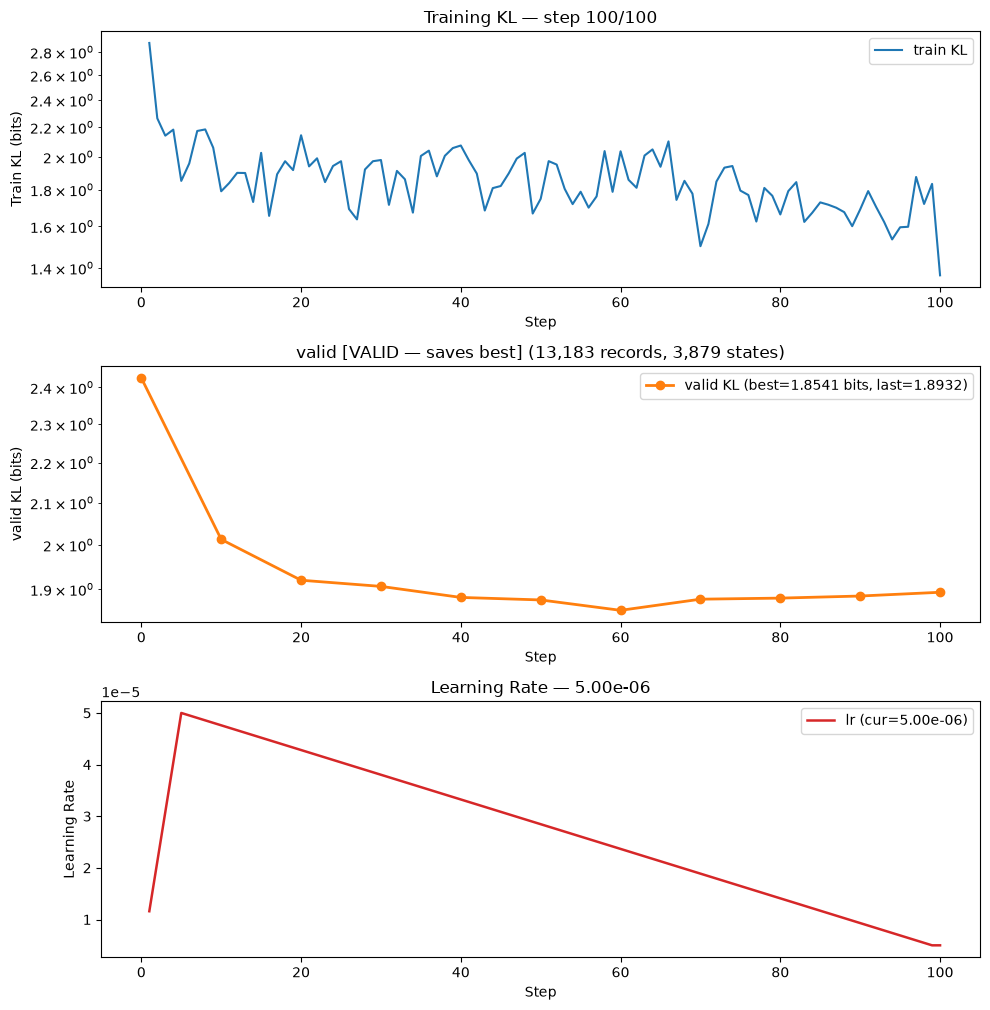

,epoch,step,train_kl,valid_kl
0,0,0,—,2.4262
1,1,10,1.7906,2.0127
2,1,20,2.1433,1.9198
3,1,30,1.9796,1.9062
4,1,40,2.0740,1.8820
5,1,50,1.7479,1.8765
6,1,60,2.0358,1.8541
7,1,70,1.5012,1.8782
8,1,80,1.6622,1.8805
9,1,90,1.6894,1.8850


In [12]:
plotter_linear_10 = run_lr_strategy(
    "linear-floor10",
    "6. Linear + 10% floor (5e-6)",
    lr_schedule="linear",
    min_lr=5e-6,
)

## Strategy 7: WSD (80% Stable @ `5e-5` → 20% Cosine Decay to `5e-6`)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,7. WSD (80% stable -> 5e-6)
run_name,test-kev-0.8b-lrtune-wsd-floor10
save_dir,runs/test-kev-0.8b-lrtune-wsd-floor10
init_from,jaredpalmer/kev-0.8b
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64
resume,False
seed,0
epochs,1
lr_schedule,wsd


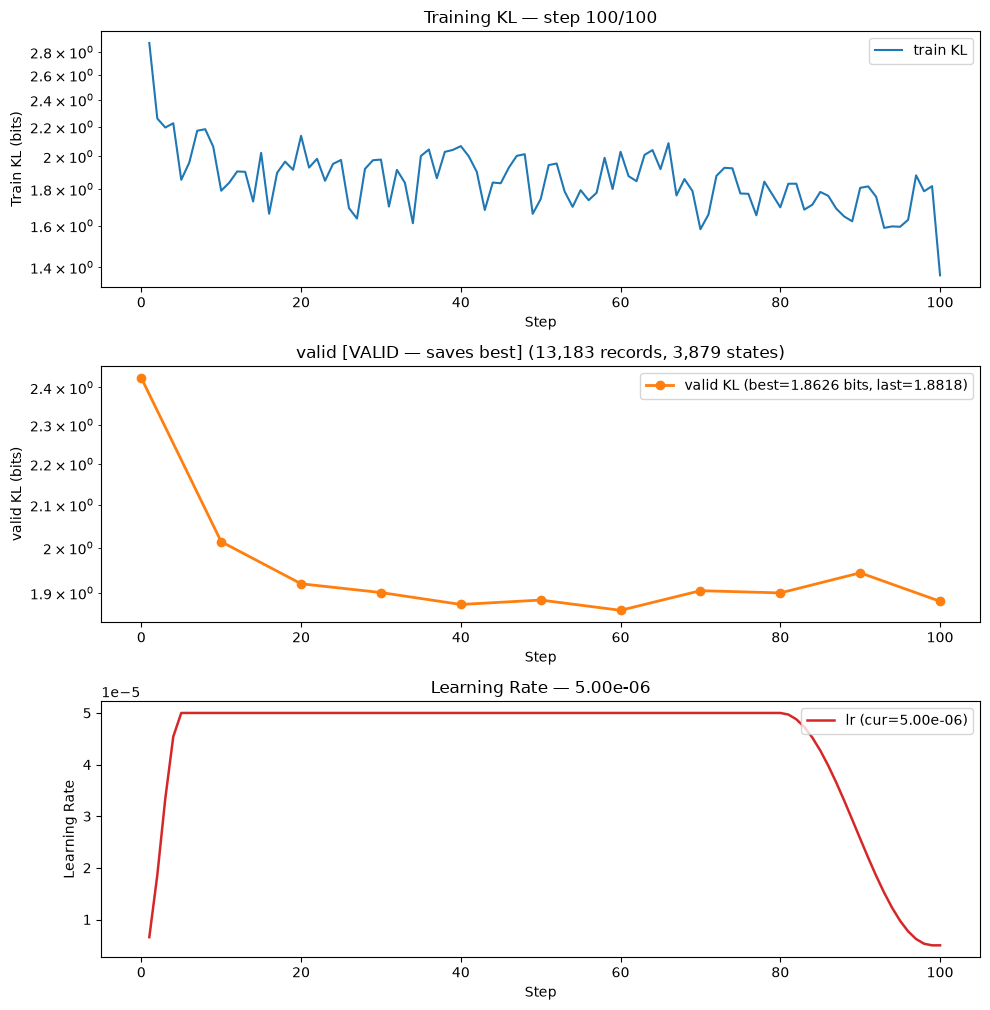

,epoch,step,train_kl,valid_kl
0,0,0,—,2.4262
1,1,10,1.7907,2.0138
2,1,20,2.1371,1.9197
3,1,30,1.9795,1.9006
4,1,40,2.0673,1.8750
5,1,50,1.7430,1.8845
6,1,60,2.0300,1.8626
7,1,70,1.5818,1.9047
8,1,80,1.6973,1.8998
9,1,90,1.8073,1.9438


In [13]:
plotter_wsd_10 = run_lr_strategy(
    "wsd-floor10",
    "7. WSD (80% stable -> 5e-6)",
    lr_schedule="wsd",
    min_lr=5e-6,
    decay_pct=0.20,
)

## 3. Compare All Executed LR Strategies (Train KL, Valid KL, and LR)

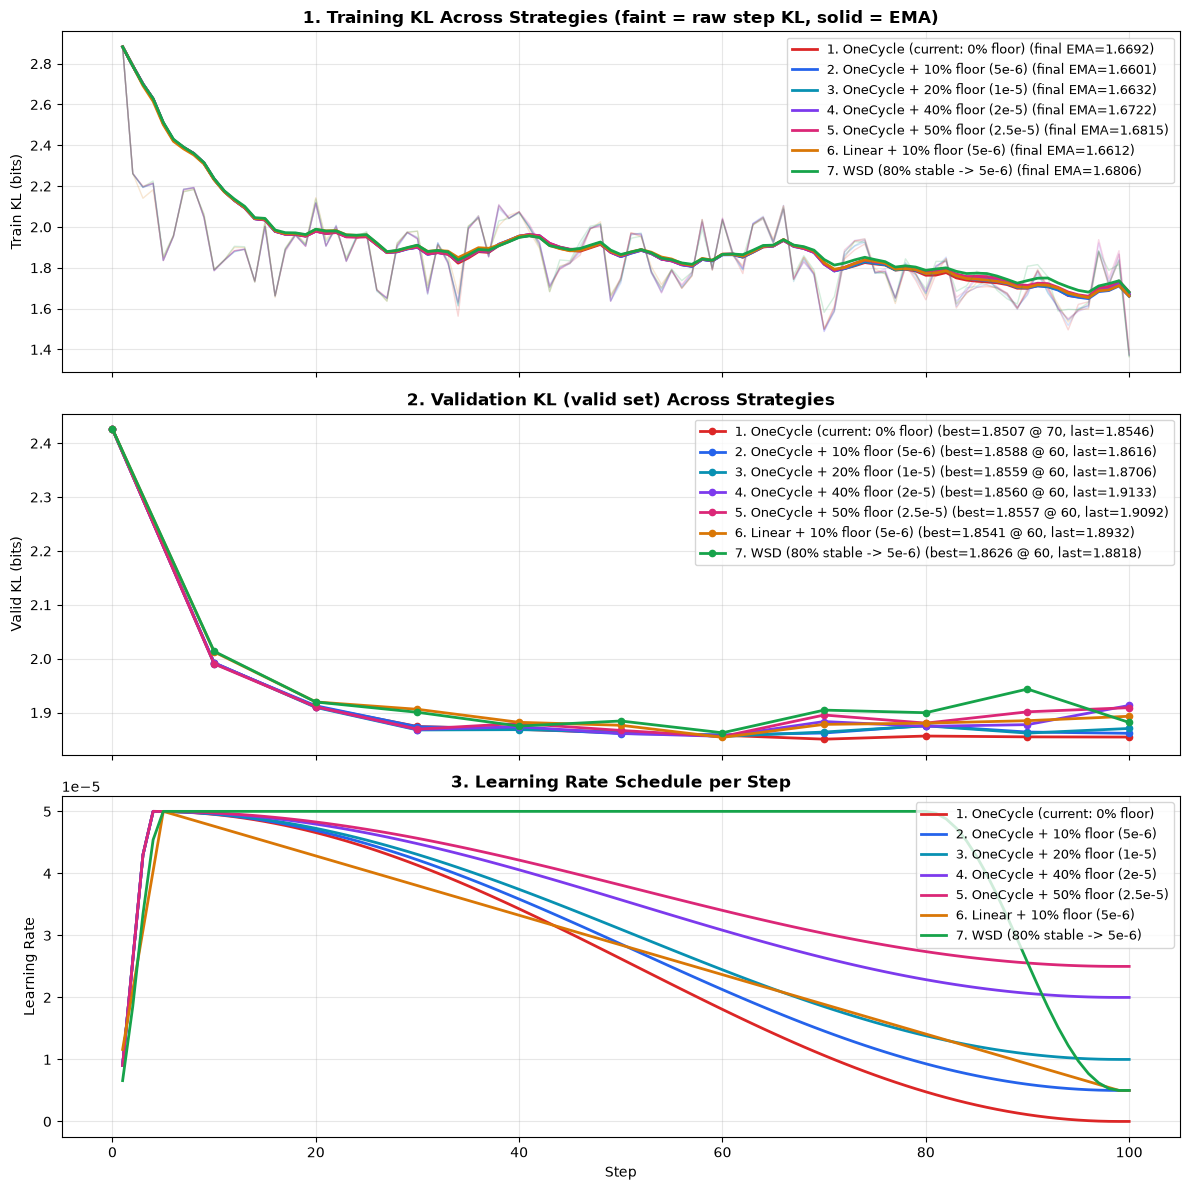

,best_valid_kl,best_step,final_valid_kl,valid_improvement_in_last_3rd,final_train_kl_ema,mean_train_kl_last_3rd,end_lr
strategy,,,,,,,
1. OneCycle (current: 0% floor),1.8507,70,1.8546,-0.0039,1.6692,1.7110,2.00e-10
2. OneCycle + 10% floor (5e-6),1.8588,60,1.8616,0.0006,1.6601,1.7109,5.00e-06
3. OneCycle + 20% floor (1e-5),1.8559,60,1.8706,-0.0066,1.6632,1.7148,1.00e-05
7. WSD (80% stable -> 5e-6),1.8626,60,1.8818,0.0229,1.6806,1.7381,5.00e-06
6. Linear + 10% floor (5e-6),1.8541,60,1.8932,-0.0151,1.6612,1.7148,5.00e-06
5. OneCycle + 50% floor (2.5e-5),1.8557,60,1.9092,-0.0136,1.6815,1.7251,2.50e-05
4. OneCycle + 40% floor (2e-5),1.8560,60,1.9133,-0.0299,1.6722,1.7202,2.00e-05


In [14]:
if not lr_tuning_runs:
    raise RuntimeError("No strategies have been run yet; execute one or more strategy cells above first.")

palette = [
    "#dc2626",  # 1. OneCycle 0%
    "#2563eb",  # 2. OneCycle 10%
    "#0891b2",  # 3. OneCycle 20%
    "#7c3aed",  # 4. OneCycle 40%
    "#db2777",  # 5. OneCycle 50%
    "#d97706",  # 6. Linear 10%
    "#16a34a",  # 7. WSD 10%
]

fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)
ax_train, ax_valid, ax_lr = axes

summary_rows = []
for idx, (label, p) in enumerate(lr_tuning_runs.items()):
    color = palette[idx % len(palette)]
    steps = np.asarray(p.history["step"], dtype=np.float64)
    train_kls = np.asarray(p.history["step_kl"], dtype=np.float64)
    lrs = np.asarray(p.history["lr"], dtype=np.float64)
    val_steps = np.asarray(p.history["val_step"], dtype=np.float64)
    val_kls = np.asarray(p.history["eval_kls"]["valid"], dtype=np.float64)

    # EMA-smoothed train KL for readability alongside faint raw trace
    ema = np.empty_like(train_kls)
    alpha = 0.15
    for i, val in enumerate(train_kls):
        ema[i] = val if i == 0 else alpha * val + (1.0 - alpha) * ema[i - 1]

    ax_train.plot(steps, train_kls, color=color, alpha=0.18, linewidth=1.0)
    ax_train.plot(steps, ema, color=color, linewidth=2.0, label=f"{label} (final EMA={ema[-1]:.4f})")

    finite_mask = np.isfinite(val_kls)
    v_xs, v_ys = val_steps[finite_mask], val_kls[finite_mask]
    best_val = float(v_ys.min())
    best_step = int(v_xs[v_ys.argmin()])
    final_val = float(v_ys[-1])
    ax_valid.plot(
        v_xs, v_ys, marker="o", markersize=4.5, linewidth=2.0, color=color,
        label=f"{label} (best={best_val:.4f} @ {best_step}, last={final_val:.4f})"
    )

    ax_lr.plot(steps, lrs, linewidth=2.0, color=color, label=label)

    t2 = len(steps) * 2 // 3
    summary_rows.append({
        "strategy": label,
        "best_valid_kl": round(best_val, 4),
        "best_step": best_step,
        "final_valid_kl": round(final_val, 4),
        "valid_improvement_in_last_3rd": round(float(v_ys[v_xs <= 70][-1] - final_val), 4) if np.any(v_xs <= 70) else np.nan,
        "final_train_kl_ema": round(float(ema[-1]), 4),
        "mean_train_kl_last_3rd": round(float(train_kls[t2:].mean()), 4),
        "end_lr": f"{lrs[-1]:.2e}",
    })

ax_train.set_title("1. Training KL Across Strategies (faint = raw step KL, solid = EMA)", fontsize=12, fontweight="bold")
ax_train.set_ylabel("Train KL (bits)")
ax_train.grid(True, alpha=0.3)
ax_train.legend(loc="upper right", fontsize=9)

ax_valid.set_title("2. Validation KL (valid set) Across Strategies", fontsize=12, fontweight="bold")
ax_valid.set_ylabel("Valid KL (bits)")
ax_valid.grid(True, alpha=0.3)
ax_valid.legend(loc="upper right", fontsize=9)

ax_lr.set_title("3. Learning Rate Schedule per Step", fontsize=12, fontweight="bold")
ax_lr.set_ylabel("Learning Rate")
ax_lr.set_xlabel("Step")
ax_lr.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax_lr.grid(True, alpha=0.3)
ax_lr.legend(loc="upper right", fontsize=9)

fig.tight_layout()
plt.show()

df_results = pd.DataFrame(summary_rows).set_index("strategy").sort_values("final_valid_kl")
display(df_results)